# VSL – nhánh Motion-based, chạy trên máy cá nhân (VS Code)

Train và so sánh 3 cấu hình: **M0** frame difference + avg (baseline), **M1** optical flow + avg, **M2** optical flow + Conv1D.

**Chuẩn bị một lần**
1. VS Code có extension **Python** và **Jupyter**.
2. Tạo môi trường Python 3.10–3.12 riêng cho đồ án (ví dụ `python -m venv .venv`), chọn nó làm kernel ở góc phải trên của notebook.
3. GPU:
   - **Linux / WSL2 + GPU NVIDIA**: ô cài đặt sẽ cài `tensorflow[and-cuda]`, TensorFlow tự dùng GPU.
   - **Windows thuần**: TensorFlow bản mới **không dùng được GPU** trên Windows, sẽ chạy bằng CPU và rất chậm. Nên chạy notebook này trong **WSL2** (VS Code: *Connect to WSL*) để dùng GPU.

**Cách chạy:** sửa ô *Cấu hình* bên dưới, rồi **Run All**. Các bước đã xong sẽ tự bỏ qua khi chạy lại (tạo split, tính chuyển động, cấu hình đã train).

## 0. Cấu hình (chỉ cần sửa ô này)

In [1]:
import os, sys, platform

DATA_ROOT = r"D:\DAT301m\dataset\data"   # thư mục chứa train/ valid/ test/ và label_mapping.pkl
WORK      = r"./vsl_motion_work"           # nơi lưu split, ảnh chuyển động (~2,7 GB) và kết quả

BATCH   = 4      # GPU 8 GB trở lên: 8 | GPU 4–6 GB: 4 | hết bộ nhớ GPU (OOM) thì giảm tiếp
WORKERS = None   # số tiến trình tính optical flow; None = tự chọn theo số nhân CPU
RUNS    = ['m0_diff_avg', 'm1_flow_avg', 'm2_diff_tconv']
EXTRA_ARGS = []  # chạy thử nhanh: ['--warmup_epochs', '1', '--epochs', '1']

# ---- không cần sửa phần dưới
DATA_ROOT   = os.path.abspath(DATA_ROOT)
WORK        = os.path.abspath(WORK)
MOTION_ROOT = os.path.join(WORK, "motion")
RUNS_DIR    = os.path.join(WORK, "runs")
SPLITS_CSV  = os.path.join(WORK, "splits.csv")
for d in (WORK, MOTION_ROOT, RUNS_DIR):
    os.makedirs(d, exist_ok=True)
CONFIGS = {
    'm0_diff_avg':   ['--mode', 'diff', '--temporal', 'avg'],
    'm1_flow_avg':   ['--mode', 'flow', '--temporal', 'avg'],
    'm2_diff_tconv': ['--mode', 'diff', '--temporal', 'tconv'],
}
print("Python  :", sys.version.split()[0], "|", platform.system())
print("DATA_ROOT:", DATA_ROOT)
print("WORK     :", WORK)

Python  : 3.10.11 | Windows
DATA_ROOT: D:\DAT301m\dataset\data
WORK     : d:\DAT301m\dataset\vsl_motion_work


## 1. Cài thư viện (chỉ cài những gói còn thiếu)
Nếu ô này có cài gì mới, hãy **Restart kernel** rồi chạy lại từ ô Cấu hình.

In [2]:
import importlib.util, subprocess
need = {"cv2": "opencv-python", "pandas": "pandas", "sklearn": "scikit-learn", "matplotlib": "matplotlib"}
missing = [pkg for mod, pkg in need.items() if importlib.util.find_spec(mod) is None]
if importlib.util.find_spec("tensorflow") is None:
    missing.append("tensorflow[and-cuda]" if platform.system() == "Linux" else "tensorflow")
if missing:
    print("Cài:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print(">>> Đã cài xong. Hãy Restart kernel rồi chạy lại từ ô Cấu hình.")
else:
    print("Đã có đủ thư viện.")

Đã có đủ thư viện.


## 2. Ghi các script
Các bước nặng chạy thành tiến trình riêng (an toàn với multiprocessing trên Windows và giải phóng GPU sau mỗi lần train).

In [3]:
%%writefile make_splits.py
"""
Tạo splits.csv từ cấu trúc thư mục đã chia sẵn, dùng ĐÚNG label_mapping.pkl của nhóm:
    <data_root>/label_mapping.pkl
    <data_root>/train/<tên lớp>/*.mp4
    <data_root>/valid/<tên lớp>/*.mp4
    <data_root>/test/<tên lớp>/*.mp4     (hoặc test/*.mp4 nếu test không có nhãn)

Cột đầu ra: path (tương đối so với data_root), label, class_name, split (train | val | test)

- KHÔNG tự tạo mapping: bắt buộc có label_mapping.pkl (mặc định <data_root>/label_mapping.pkl).
- So khớp tên thư mục lớp với mapping sau khi chuẩn hóa Unicode NFC + bỏ khoảng trắng hai đầu
  (tránh lệch NFC/NFD giữa Windows/macOS/Linux). Lớp nào không có trong mapping -> dừng, không đoán.
- Kiểm tra rò rỉ: báo các file giống hệt từng byte nằm ở hai tập khác nhau.
"""
import argparse
import hashlib
import json
import os
import pickle
import unicodedata

import numpy as np
import pandas as pd

SPLITS = {"train": "train", "valid": "val", "val": "val", "test": "test"}
EXTS = (".mp4", ".avi", ".mov", ".mkv")


def norm(s):
    return unicodedata.normalize("NFC", str(s)).strip()


def is_int_like(x):
    return isinstance(x, (int, np.integer)) or (isinstance(x, str) and x.strip().lstrip("-").isdigit())


def load_mapping(path):
    """Trả về dict {tên lớp đã chuẩn hóa: id}. Chấp nhận các dạng thường gặp:
    {tên: id}, {id: tên}, list/tuple/array tên (vị trí = id), LabelEncoder (classes_),
    hoặc dict bọc ngoài có khóa như label2id / class_to_idx / id2label."""
    with open(path, "rb") as fh:
        obj = pickle.load(fh)  # chỉ dùng với file do chính nhóm tạo

    if hasattr(obj, "classes_"):  # sklearn LabelEncoder
        obj = list(obj.classes_)
    if isinstance(obj, dict):
        for k in ("label2id", "class_to_idx", "label_to_idx", "name2id", "id2label", "idx_to_class"):
            if k in obj and isinstance(obj[k], (dict, list, tuple)):
                obj = obj[k]
                break
    if isinstance(obj, (list, tuple, np.ndarray)):
        obj = {i: name for i, name in enumerate(obj)}
    if not isinstance(obj, dict):
        raise SystemExit(f"Không hiểu định dạng label_mapping: {type(obj)}")

    keys_int = all(is_int_like(k) for k in obj)
    vals_int = all(is_int_like(v) for v in obj.values())
    if keys_int and not vals_int:          # {id: tên}
        m = {norm(v): int(k) for k, v in obj.items()}
    elif vals_int and not keys_int:        # {tên: id}
        m = {norm(k): int(v) for k, v in obj.items()}
    else:
        raise SystemExit("label_mapping phải là {tên: id} hoặc {id: tên}; "
                         f"ví dụ phần tử đầu: {list(obj.items())[:3]}")

    if len(m) != len(obj):
        raise SystemExit("label_mapping có tên lớp trùng nhau sau khi chuẩn hóa Unicode")
    ids = sorted(m.values())
    if ids != list(range(len(ids))):
        raise SystemExit(f"ID trong label_mapping không liên tục 0..{len(ids) - 1}: {ids[:5]}...{ids[-5:]}")
    return m


def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_root", required=True)
    ap.add_argument("--out", default="splits.csv")
    ap.add_argument("--mapping", default=None, help="mặc định: <data_root>/label_mapping.pkl")
    ap.add_argument("--skip_leak_check", action="store_true")
    args = ap.parse_args()

    mapping_path = args.mapping or os.path.join(args.data_root, "label_mapping.pkl")
    if not os.path.exists(mapping_path):
        raise SystemExit(f"Không thấy {mapping_path}. Script không tự tạo mapping, hãy chỉ đúng --mapping.")
    mapping = load_mapping(mapping_path)
    print(f"Mapping: {mapping_path} | {len(mapping)} lớp | ví dụ: "
          + ", ".join(f"{i}={n}" for n, i in sorted(mapping.items(), key=lambda t: t[1])[:3]))

    rows = []
    for d in sorted(os.listdir(args.data_root)):
        split = SPLITS.get(d.lower())
        if split is None or not os.path.isdir(os.path.join(args.data_root, d)):
            continue
        for dirpath, _, files in os.walk(os.path.join(args.data_root, d)):
            for f in sorted(files):
                if not f.lower().endswith(EXTS):
                    continue
                full = os.path.join(dirpath, f)
                rel = os.path.relpath(full, args.data_root)
                parts = rel.split(os.sep)
                cls = norm(parts[1]) if len(parts) >= 3 else None
                rows.append(dict(path=rel, class_name=cls, split=split, full=full))
    df = pd.DataFrame(rows)
    if df.empty:
        raise SystemExit("Không tìm thấy video nào, kiểm tra lại --data_root")

    folders = set(df.class_name.dropna())
    unknown = sorted(folders - set(mapping))
    if unknown:
        raise SystemExit(f"{len(unknown)} thư mục lớp không có trong label_mapping (không tự gán): {unknown[:10]}")
    unused = sorted(set(mapping) - set(df[df.split == "train"].class_name.dropna()))
    if unused:
        print(f"CẢNH BÁO: {len(unused)} lớp trong mapping không có video train: {unused[:10]}")

    df["label"] = [mapping[c] if c is not None else -1 for c in df.class_name]
    print(df.groupby("split").agg(videos=("path", "size"), classes=("class_name", "nunique")))

    if not args.skip_leak_check:
        df["md5"] = [md5(p) for p in df.full]
        cross = df.groupby("md5").split.nunique()
        leak = df[df.md5.isin(cross[cross > 1].index)]
        if len(leak):
            print(f"CẢNH BÁO rò rỉ: {leak.md5.nunique()} nội dung giống hệt xuất hiện ở nhiều tập "
                  f"({len(leak)} file). Ví dụ:")
            print(leak.sort_values("md5")[["split", "path"]].head(10).to_string(index=False))
        else:
            print("Không có file trùng byte giữa các tập.")

    df[["path", "label", "class_name", "split"]].to_csv(args.out, index=False)
    # Lưu kèm số lớp + thứ tự tên lớp để train_motion.py dùng đúng theo mapping
    meta = os.path.splitext(args.out)[0] + "_classes.json"
    with open(meta, "w", encoding="utf-8") as fh:
        json.dump([n for n, _ in sorted(mapping.items(), key=lambda t: t[1])], fh, ensure_ascii=False, indent=0)
    print(f"Đã ghi {args.out} và {meta}")


if __name__ == "__main__":
    main()


Overwriting make_splits.py


In [4]:
%%writefile precompute_motion.py
"""
Bước 1 – Tiền tính chuyển động cho từng video (chạy 1 lần, offline).

Với mỗi video:
  1. Đọc toàn bộ frame gốc (thường 30 frame).
  2. LOẠI frame đồng màu (std mỗi kênh <= 1/255) TRƯỚC khi tính chuyển động.
     Nếu không, cặp (frame đen -> frame có người) sẽ sinh ra optical flow giả rất lớn.
  3. Tính trên các cặp frame LIÊN TIẾP:
       - optical flow Farneback (u, v)  -> dùng cho mô hình flow
       - |frame_t - frame_{t-1}| (gray) -> dùng cho baseline frame-difference
  4. Lượng tử flow về uint8 (cắt ở ±BOUND pixel) và lưu .npz nén.

Lấy mẫu 16 bước thời gian được làm SAU, lúc train (để còn augment tốc độ).

Input: một CSV có cột `path` (đường dẫn video, tuyệt đối hoặc tương đối so với --data_root).
Nên dùng đúng CSV chia tập theo nhóm mà nhóm đã tạo ở mục 4.3 (đã loại 9 video lỗi).

Ví dụ:
  python precompute_motion.py --csv splits.csv --data_root /data/vsl --out_root /data/vsl_motion
"""
import argparse
import os
import shutil
import tempfile
import time
from multiprocessing import Pool

import cv2
import numpy as np
import pandas as pd

BOUND = 20.0  # pixel; flow ngoài ±BOUND bị cắt. Xem clip_ratio trong motion_stats.csv để chỉnh.


def _read(path):
    cap = cv2.VideoCapture(path)
    frames = []
    while True:
        ok, f = cap.read()
        if not ok:
            break
        frames.append(f)
    cap.release()
    return frames


def read_frames(path):
    frames = _read(path)
    if not frames and not path.isascii():
        # OpenCV trên Windows thường không mở được đường dẫn có ký tự tiếng Việt
        # -> chép tạm sang một file tên ASCII rồi đọc.
        fd, tmp = tempfile.mkstemp(suffix=os.path.splitext(path)[1])
        os.close(fd)
        try:
            shutil.copyfile(path, tmp)
            frames = _read(tmp)
        finally:
            os.remove(tmp)
    return frames


def _init_worker():
    cv2.setNumThreads(1)


def is_blank(frame_bgr):
    # cùng tiêu chí với mục 4.2: độ lệch chuẩn từng kênh <= 1/255 (tức <= 1 trên thang uint8)
    return bool((frame_bgr.reshape(-1, 3).std(axis=0) <= 1.0).all())


def out_path_for(video_path, data_root, out_root):
    rel = os.path.relpath(video_path, data_root)
    return os.path.join(out_root, os.path.splitext(rel)[0] + ".npz")


def process(job):
    video_path, out_path, size = job
    if os.path.exists(out_path):
        return None
    t0 = time.time()
    frames = read_frames(video_path)
    kept = [f for f in frames if not is_blank(f)]
    gray = [
        cv2.cvtColor(cv2.resize(f, (size, size), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY)
        for f in kept
    ]

    flows, diffs = [], []
    for a, b in zip(gray[:-1], gray[1:]):
        # FPS chỉ ~12 nên chuyển động giữa 2 frame khá lớn -> dùng nhiều tầng pyramid + cửa sổ rộng
        flow = cv2.calcOpticalFlowFarneback(
            a, b, None, pyr_scale=0.5, levels=5, winsize=21,
            iterations=3, poly_n=5, poly_sigma=1.2, flags=0,
        )
        flows.append(flow)
        diffs.append(cv2.absdiff(b, a))

    if flows:
        flow = np.stack(flows)  # (n, H, W, 2) float32, đơn vị pixel
        clip_ratio = float((np.abs(flow) > BOUND).mean())
        q = np.round((np.clip(flow, -BOUND, BOUND) + BOUND) / (2 * BOUND) * 255).astype(np.uint8)
        diff = np.stack(diffs)  # (n, H, W) uint8
    else:  # video gần như toàn frame trống -> chuyển động bằng 0
        clip_ratio = 0.0
        q = np.full((1, size, size, 2), 128, np.uint8)
        diff = np.zeros((1, size, size), np.uint8)

    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    np.savez_compressed(out_path, flow=q, diff=diff)
    return dict(
        video=video_path, npz=out_path, n_frames=len(frames),
        n_blank=len(frames) - len(kept), n_motion=len(q),
        clip_ratio=clip_ratio, sec=time.time() - t0,
    )


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--csv", required=True)
    ap.add_argument("--data_root", required=True)
    ap.add_argument("--out_root", required=True)
    ap.add_argument("--size", type=int, default=224)
    ap.add_argument("--workers", type=int, default=max(1, min(8, (os.cpu_count() or 2) - 1)))
    args = ap.parse_args()

    df = pd.read_csv(args.csv)
    paths = [p if os.path.isabs(p) else os.path.join(args.data_root, p) for p in df["path"]]
    jobs = [(p, out_path_for(p, args.data_root, args.out_root), args.size) for p in paths]

    rows = []
    with Pool(args.workers, initializer=_init_worker) as pool:
        for i, r in enumerate(pool.imap_unordered(process, jobs, chunksize=4)):
            if r:
                rows.append(r)
            if (i + 1) % 200 == 0:
                print(f"{i + 1}/{len(jobs)} video")

    os.makedirs(args.out_root, exist_ok=True)
    if rows:
        st = pd.DataFrame(rows)
        st.to_csv(os.path.join(args.out_root, "motion_stats.csv"), index=False)
        print(f"Xong {len(st)} video | {st.sec.mean() * 1000:.0f} ms/video (1 CPU core)")
        print(f"Video có frame trống đã bị bỏ: {(st.n_blank > 0).sum()}")
        bad = st[st.n_frames == 0]
        if len(bad):
            print(f"CẢNH BÁO: {len(bad)} video không đọc được frame nào (đã lưu chuyển động = 0), "
                  f"xem motion_stats.csv, ví dụ: {bad.video.iloc[0]}")
        print(f"Tỷ lệ flow bị cắt ở ±{BOUND:.0f}px: trung bình {st.clip_ratio.mean():.5f}, "
              f"p99 {st.clip_ratio.quantile(0.99):.5f} (nếu p99 > ~0.01 thì tăng BOUND)")


if __name__ == "__main__":
    main()


Overwriting precompute_motion.py


In [5]:
%%writefile train_motion.py
"""
Bước 2 – Train mô hình motion-based (TensorFlow/Keras).

Kiến trúc (kiểu TSN / two-stream, nhánh motion):
  clip chuyển động (T=16, 224, 224, 3)
    -> TimeDistributed(CNN 2D pretrained ImageNet)   : đặc trưng không gian từng bước
    -> mô-đun thời gian: avg | tconv | gru            : gộp thông tin theo thời gian
    -> Dense(100) logits

Đầu vào chuyển động, chọn bằng --mode:
  diff : |frame_t - frame_{t-1}| lặp thành 3 kênh                (baseline, rẻ nhất)
  flow : optical flow mã hóa 3 kênh (u, v, độ lớn) trong [-1, 1]  (để dùng thẳng trọng số ImageNet)

CSV cần các cột: path, label (0–99; test để -1), split (train | val | public_test | private_test).
Dùng đúng file chia tập theo nhóm của cả nhóm để so sánh công bằng với RGB/landmark.

Ví dụ:
  # M0 – baseline frame difference
  python train_motion.py --csv splits.csv --data_root /data/vsl --motion_root /data/vsl_motion \
      --mode diff --temporal avg --out runs/m0_diff_avg
  # M1 – optical flow + trung bình thời gian
  python train_motion.py ... --mode flow --temporal avg   --out runs/m1_flow_avg
  # M2 – optical flow + temporal conv
  python train_motion.py ... --mode flow --temporal tconv --out runs/m2_flow_tconv
"""
import argparse
import json
import os
import time

import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)

NUM_CLASSES = 100
DIFF_GAIN = 4.0  # frame difference thường rất nhỏ -> khuếch đại trước khi đưa vào CNN


# ----------------------------------------------------------------------------- dữ liệu
def npz_path(p, data_root, motion_root):
    p = p if os.path.isabs(p) else os.path.join(data_root, p)
    rel = os.path.relpath(p, data_root)
    return os.path.join(motion_root, os.path.splitext(rel)[0] + ".npz")


def load_clip(path, mode, T, S, train, rng):
    d = np.load(path)
    raw = d["flow"] if mode == "flow" else d["diff"]
    n = raw.shape[0]

    # Lấy đều T bước; train thì co giãn tốc độ 0.9–1.1 (giống mục 4.3c). n < T thì tự lặp bước.
    s = rng.uniform(0.9, 1.1) if train else 1.0
    idx = np.clip(np.round(np.linspace(0, n - 1, T) * s), 0, n - 1).astype(np.int64)
    raw = raw[idx]

    if mode == "flow":
        x = raw.astype(np.float32) / 255.0 * 2.0 - 1.0  # (T,H,W,2) ≈ flow / BOUND
    else:
        x = (np.minimum(raw.astype(np.float32) * DIFF_GAIN, 255.0) / 255.0)[..., None]  # (T,H,W,1)

    # Random crop giữ 85–100% diện tích, cùng vị trí cho mọi bước thời gian.
    H, W = x.shape[1:3]
    if train:
        c = int(round(min(H, W) * np.sqrt(rng.uniform(0.85, 1.0))))
        y0, x0 = int(rng.integers(0, H - c + 1)), int(rng.integers(0, W - c + 1))
        x = x[:, y0:y0 + c, x0:x0 + c]

    ch, cw = x.shape[1:3]
    if (ch, cw) != (S, S):
        x = np.stack([cv2.resize(f, (S, S), interpolation=cv2.INTER_LINEAR) for f in x])
        if x.ndim == 3:
            x = x[..., None]
        if mode == "flow":
            # phóng to ảnh thì vector dịch chuyển cũng phải phóng to theo
            x[..., 0] *= S / cw
            x[..., 1] *= S / ch

    if mode == "flow":
        x = np.clip(x, -1.0, 1.0)
        mag = np.sqrt(x[..., 0] ** 2 + x[..., 1] ** 2) / np.sqrt(2.0)  # [0, 1]
        x = np.concatenate([x, mag[..., None] * 2.0 - 1.0], axis=-1)
    else:
        x = np.repeat(x * 2.0 - 1.0, 3, axis=-1)
    return x.astype(np.float32)  # (T, S, S, 3) trong [-1, 1]


class BalancedIndices:
    """Tương đương WeightedRandomSampler: trọng số 1/n_c, có hoàn lại, N mẫu mỗi epoch."""

    def __init__(self, labels, seed):
        counts = np.bincount(labels, minlength=NUM_CLASSES)
        w = 1.0 / counts[labels]
        self.p, self.n, self.seed, self.epoch = w / w.sum(), len(labels), seed, 0

    def __call__(self):
        rng = np.random.default_rng(self.seed + self.epoch)
        self.epoch += 1
        idx = rng.choice(self.n, size=self.n, replace=True, p=self.p)
        seeds = rng.integers(0, 2 ** 31 - 1, size=self.n)
        for i, s in zip(idx, seeds):
            yield int(i), int(s)


def make_ds(paths, labels, args, train, sampler=None):
    def _load(i, s):
        x = load_clip(paths[int(i)], args.mode, args.T, args.size, train, np.random.default_rng(int(s)))
        return x, np.int64(labels[int(i)])

    def _map(i, s):
        x, y = tf.numpy_function(_load, [i, s], [tf.float32, tf.int64])
        x.set_shape((args.T, args.size, args.size, 3))
        y.set_shape(())
        return x, tf.one_hot(y, NUM_CLASSES)

    spec = (tf.TensorSpec((), tf.int64), tf.TensorSpec((), tf.int64))
    if train:
        ds = tf.data.Dataset.from_generator(sampler, output_signature=spec)
    else:
        n = len(paths)
        ds = tf.data.Dataset.from_tensor_slices((np.arange(n, dtype=np.int64), np.zeros(n, np.int64)))
    ds = ds.map(_map, num_parallel_calls=tf.data.AUTOTUNE, deterministic=not train)
    return ds.batch(args.bs, drop_remainder=train).prefetch(tf.data.AUTOTUNE)


# ----------------------------------------------------------------------------- mô hình
def build_model(args):
    weights = None if args.no_pretrained else "imagenet"
    inp = keras.Input((args.T, args.size, args.size, 3))
    if args.backbone == "mobilenetv2":
        bb = keras.applications.MobileNetV2(include_top=False, weights=weights,
                                            input_shape=(args.size, args.size, 3), pooling="avg")
        x = inp  # MobileNetV2 nhận đầu vào [-1, 1]
    else:
        bb = keras.applications.EfficientNetB0(include_top=False, weights=weights,
                                               input_shape=(args.size, args.size, 3), pooling="avg")
        x = layers.Rescaling(127.5, offset=127.5)(inp)  # EfficientNet của Keras nhận [0, 255]

    f = layers.TimeDistributed(bb, name="frame_encoder")(x)  # (B, T, D)
    f = layers.Dropout(0.3)(f)
    if args.temporal == "avg":
        h = layers.GlobalAveragePooling1D()(f)
    elif args.temporal == "gru":
        h = layers.Bidirectional(layers.GRU(256))(f)
    else:  # tconv: 2 lớp Conv1D theo trục thời gian
        h = layers.Conv1D(256, 3, padding="same", activation="relu")(f)
        h = layers.Dropout(0.3)(h)
        h = layers.Conv1D(256, 3, padding="same", activation="relu")(h)
        h = layers.GlobalAveragePooling1D()(h)
    h = layers.Dropout(0.4)(h)
    out = layers.Dense(NUM_CLASSES, dtype="float32", name="logits")(h)
    return keras.Model(inp, out), bb


def set_backbone_trainable(bb, trainable):
    bb.trainable = trainable
    if trainable:  # giữ BatchNorm đóng băng: batch nhỏ, các frame trong clip tương quan mạnh
        for l in bb.layers:
            if isinstance(l, layers.BatchNormalization):
                l.trainable = False


class MacroF1Checkpoint(keras.callbacks.Callback):
    """Chọn mô hình theo Macro-F1 trên validation (chỉ số của cuộc thi) + early stopping."""

    def __init__(self, val_ds, y_val, out_path, patience):
        super().__init__()
        self.val_ds, self.y_val, self.out_path, self.patience = val_ds, y_val, out_path, patience
        self.best, self.wait = -1.0, 0

    def on_epoch_end(self, epoch, logs=None):
        pred = self.model.predict(self.val_ds, verbose=0).argmax(1)
        f1 = f1_score(self.y_val, pred, average="macro", labels=np.arange(NUM_CLASSES), zero_division=0)
        acc = accuracy_score(self.y_val, pred)
        if logs is not None:
            logs["val_macro_f1"], logs["val_top1"] = f1, acc
        print(f"  epoch {epoch + 1}: val macro-F1 {f1:.4f} | val top-1 {acc:.4f}")
        if f1 > self.best:
            self.best, self.wait = f1, 0
            self.model.save_weights(self.out_path)
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.model.stop_training = True


def softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)


# ----------------------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--csv", required=True)
    ap.add_argument("--data_root", required=True)
    ap.add_argument("--motion_root", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--mode", choices=["flow", "diff"], default="flow")
    ap.add_argument("--backbone", choices=["mobilenetv2", "efficientnetb0"], default="mobilenetv2")
    ap.add_argument("--temporal", choices=["avg", "tconv", "gru"], default="avg")
    ap.add_argument("--T", type=int, default=16)
    ap.add_argument("--size", type=int, default=224)
    ap.add_argument("--bs", type=int, default=8)
    ap.add_argument("--warmup_epochs", type=int, default=3, help="giai đoạn 1: đóng băng backbone")
    ap.add_argument("--epochs", type=int, default=30, help="giai đoạn 2: fine-tune toàn bộ")
    ap.add_argument("--lr", type=float, default=1e-4)
    ap.add_argument("--patience", type=int, default=8)
    ap.add_argument("--seed", type=int, default=42)
    ap.add_argument("--mixed_precision", action="store_true")
    ap.add_argument("--no_pretrained", action="store_true", help="chỉ dùng để chạy thử")
    ap.add_argument("--eval_only", action="store_true",
                    help="bỏ qua train, nạp <out>/best.weights.h5 rồi đánh giá lại + đo thời gian")
    args = ap.parse_args()

    os.makedirs(args.out, exist_ok=True)
    keras.utils.set_random_seed(args.seed)
    gpus = tf.config.list_physical_devices("GPU")
    print(f"GPU: {len(gpus)}" + ("" if gpus else "  (đang chạy trên CPU, sẽ rất chậm)"))
    for g in gpus:
        try:
            tf.config.experimental.set_memory_growth(g, True)
        except RuntimeError:
            pass
    if args.mixed_precision and gpus:
        keras.mixed_precision.set_global_policy("mixed_float16")

    global NUM_CLASSES
    classes_json = os.path.splitext(args.csv)[0] + "_classes.json"
    class_names = None
    if os.path.exists(classes_json):  # sinh bởi make_splits.py từ label_mapping.pkl
        with open(classes_json, encoding="utf-8") as fh:
            class_names = json.load(fh)
        NUM_CLASSES = len(class_names)
    print(f"Số lớp: {NUM_CLASSES}" + (f" (theo {classes_json})" if class_names else ""))

    df = pd.read_csv(args.csv)
    df["npz"] = [npz_path(p, args.data_root, args.motion_root) for p in df["path"]]
    missing = df[~df["npz"].map(os.path.exists)]
    if len(missing):
        raise SystemExit(f"{len(missing)} video chưa có file .npz, hãy chạy precompute_motion.py trước")
    tr = df[df.split == "train"].reset_index(drop=True)
    va = df[df.split == "val"].reset_index(drop=True)
    y_tr, y_va = tr.label.values.astype(np.int64), va.label.values.astype(np.int64)
    print(f"train {len(tr)} | val {len(va)}")

    train_ds = make_ds(tr.npz.values, y_tr, args, True, BalancedIndices(y_tr, args.seed))
    val_ds = make_ds(va.npz.values, y_va, args, False)

    model, bb = build_model(args)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True, label_smoothing=0.1)
    best_path = os.path.join(args.out, "best.weights.h5")
    ckpt = MacroF1Checkpoint(val_ds, y_va, best_path, args.patience)
    logger = keras.callbacks.CSVLogger(os.path.join(args.out, "history.csv"), append=True)

    if args.eval_only:
        if not os.path.exists(best_path):
            raise SystemExit(f"Không thấy {best_path}")
        print("eval_only: bỏ qua train")
    else:
        train(model, bb, train_ds, loss, ckpt, logger, args, len(tr))

    evaluate_all(model, df, va, y_va, best_path, class_names, args)


def train(model, bb, train_ds, loss, ckpt, logger, args, n_train):
    # Giai đoạn 1: chỉ train phần thời gian + classifier
    set_backbone_trainable(bb, False)
    model.compile(optimizer=keras.optimizers.AdamW(1e-3, weight_decay=1e-4),
                  loss=loss, metrics=["accuracy"])
    model.fit(train_ds, epochs=args.warmup_epochs, callbacks=[ckpt, logger], verbose=2)

    # Giai đoạn 2: mở backbone, learning rate nhỏ, cosine decay
    set_backbone_trainable(bb, True)
    steps = max(1, n_train // args.bs)
    sched = keras.optimizers.schedules.CosineDecay(args.lr, decay_steps=steps * args.epochs)
    model.compile(optimizer=keras.optimizers.AdamW(sched, weight_decay=1e-4),
                  loss=loss, metrics=["accuracy"])
    ckpt.wait = 0
    model.fit(train_ds, initial_epoch=args.warmup_epochs,
              epochs=args.warmup_epochs + args.epochs, callbacks=[ckpt, logger], verbose=2)


def evaluate_all(model, df, va, y_va, best_path, class_names, args):
    # ---------------- đánh giá mô hình tốt nhất
    model.load_weights(best_path)

    def predict(sub, name):
        labels = sub.label.values.astype(np.int64) if "label" in sub else np.full(len(sub), -1)
        probs = softmax(model.predict(make_ds(sub.npz.values, labels, args, False), verbose=0))
        np.save(os.path.join(args.out, f"{name}_probs.npy"), probs)  # dùng cho late fusion
        sub[["path"]].assign(pred=probs.argmax(1)).to_csv(
            os.path.join(args.out, f"{name}_pred.csv"), index=False)
        return probs

    labs = np.arange(NUM_CLASSES)
    names = class_names
    if names is None and "class_name" in df.columns:
        m = df.dropna(subset=["class_name"]).groupby("label")["class_name"].first()
        names = [str(m.get(i, i)) for i in labs]

    def evaluate(sub, name):
        y = sub.label.values.astype(np.int64)
        pred = predict(sub, name).argmax(1)
        res = dict(
            top1=accuracy_score(y, pred),
            macro_f1=f1_score(y, pred, average="macro", labels=labs, zero_division=0),
            macro_precision=precision_score(y, pred, average="macro", labels=labs, zero_division=0),
            macro_recall=recall_score(y, pred, average="macro", labels=labs, zero_division=0),
        )
        with open(os.path.join(args.out, f"{name}_report.txt"), "w", encoding="utf-8") as fh:
            fh.write(classification_report(y, pred, labels=labs, target_names=names, zero_division=0))
        cm = confusion_matrix(y, pred, labels=labs)
        np.save(os.path.join(args.out, f"{name}_confusion.npy"), cm)
        off = cm.copy()
        np.fill_diagonal(off, 0)
        top = np.dstack(np.unravel_index(np.argsort(-off, axis=None)[:20], off.shape))[0]
        pd.DataFrame([dict(true=names[t] if names else t, pred=names[p] if names else p, count=off[t, p])
                      for t, p in top if off[t, p] > 0]).to_csv(
            os.path.join(args.out, f"{name}_top_confusions.csv"), index=False)
        return res

    metrics = {"val": evaluate(va, "val")}
    for split in ["test", "public_test", "private_test"]:
        sub = df[df.split == split].reset_index(drop=True)
        if not len(sub):
            continue
        if (sub.label >= 0).all():
            metrics[split] = evaluate(sub, split)  # test có nhãn -> chấm điểm luôn
        else:
            predict(sub, split)

    # Thời gian suy luận của riêng mô hình cho 1 clip (chưa tính thời gian tính flow).
    # Dùng tf.function (đồ thị đã biên dịch) + .numpy() để chờ GPU chạy xong; gọi model() ở
    # chế độ eager như bản cũ đo cả overhead Python nên ra số lớn bất thường.
    infer = tf.function(lambda x: model(x, training=False))
    dummy = tf.zeros((1, args.T, args.size, args.size, 3))
    for _ in range(5):
        infer(dummy).numpy()
    times = []
    for _ in range(30):
        t0 = time.perf_counter()
        infer(dummy).numpy()
        times.append((time.perf_counter() - t0) * 1000)
    metrics["model_ms_per_clip"] = float(np.median(times))
    metrics["device"] = "GPU" if tf.config.list_physical_devices("GPU") else "CPU"
    metrics["config"] = vars(args)

    with open(os.path.join(args.out, "metrics.json"), "w") as fh:
        json.dump(metrics, fh, indent=2, default=str)
    print(json.dumps({k: v for k, v in metrics.items() if k != "config"}, indent=2))


if __name__ == "__main__":
    main()


Overwriting train_motion.py


In [6]:
import subprocess, threading, time, json

def run(script, args, log=None, prefix="", env_extra=None, show=lambda line: True):
    """Chạy script bằng đúng Python của kernel, in output trực tiếp, ghi log (UTF-8)."""
    env = dict(os.environ, PYTHONIOENCODING="utf-8", PYTHONUTF8="1", TF_CPP_MIN_LOG_LEVEL="2")
    env.update(env_extra or {})
    p = subprocess.Popen([sys.executable, script, *map(str, args)], stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, env=env, text=True, encoding="utf-8",
                         errors="replace", bufsize=1)
    fh = open(log, "w", encoding="utf-8") if log else None
    tail = []
    for line in p.stdout:
        tail = (tail + [line])[-25:]
        if fh:
            fh.write(line); fh.flush()
        if show(line):
            print(prefix + line, end="", flush=True)
    rc = p.wait()
    if fh:
        fh.close()
    if rc != 0:
        print(f"{prefix}LỖI (mã thoát {rc}). 25 dòng cuối:\n" + "".join(prefix + l for l in tail))
    return rc

## 3. Kiểm tra môi trường và dữ liệu

In [7]:
import cv2, glob
assert os.path.isdir(DATA_ROOT), f"Không thấy DATA_ROOT: {DATA_ROOT}"
for d in sorted(os.listdir(DATA_ROOT)):
    p = os.path.join(DATA_ROOT, d)
    print(f"  {d}/: {len(os.listdir(p))} lớp" if os.path.isdir(p) else f"  {d}")
assert os.path.exists(os.path.join(DATA_ROOT, "label_mapping.pkl")), "Thiếu label_mapping.pkl trong DATA_ROOT"

# Đọc thử 1 video (đường dẫn có tiếng Việt) bằng đúng hàm của precompute_motion.py
from precompute_motion import read_frames
vids = [v for v in glob.glob(os.path.join(DATA_ROOT, "train", "*", "*")) if v.lower().endswith((".mp4", ".avi", ".mov", ".mkv"))]
frames = read_frames(vids[0])
print(f"Đọc thử: {len(frames)} frame, kích thước {frames[0].shape if frames else None} | {vids[0]}")
assert frames, "Không đọc được video. Kiểm tra opencv-python / codec."

# GPU (kiểm tra trong tiến trình riêng để kernel không giữ bộ nhớ GPU)
out = subprocess.run([sys.executable, "-c",
    "import tensorflow as tf; print(tf.__version__, len(tf.config.list_physical_devices('GPU')))"],
    capture_output=True, text=True, env=dict(os.environ, TF_CPP_MIN_LOG_LEVEL="3")).stdout.split()
TF_VERSION, N_GPU = (out[-2], int(out[-1])) if len(out) >= 2 else ("?", 0)
print(f"TensorFlow {TF_VERSION} | số GPU TensorFlow thấy: {N_GPU}")
if N_GPU == 0:
    print("CẢNH BÁO: không có GPU -> train bằng CPU, mỗi cấu hình có thể mất nhiều giờ đến cả ngày."
          + (" Trên Windows, hãy chạy notebook trong WSL2 để dùng GPU." if platform.system() == "Windows" else ""))

  label_mapping.pkl
  test/: 100 lớp
  train/: 100 lớp
  valid/: 100 lớp
Đọc thử: 30 frame, kích thước (224, 224, 3) | D:\DAT301m\dataset\data\train\An ủi\126225.mp4
TensorFlow 2.21.0 | số GPU TensorFlow thấy: 0
CẢNH BÁO: không có GPU -> train bằng CPU, mỗi cấu hình có thể mất nhiều giờ đến cả ngày. Trên Windows, hãy chạy notebook trong WSL2 để dùng GPU.


## 4. Tạo splits.csv theo `label_mapping.pkl` (không tự tạo mapping)

In [8]:
if os.path.exists(SPLITS_CSV):
    print("Đã có", SPLITS_CSV, "-> bỏ qua (xoá file này nếu muốn tạo lại)")
else:
    rc = run("make_splits.py", ["--data_root", DATA_ROOT, "--mapping", os.path.join(DATA_ROOT, "label_mapping.pkl"),
                                "--out", SPLITS_CSV])
    assert rc == 0

Đã có d:\DAT301m\dataset\vsl_motion_work\splits.csv -> bỏ qua (xoá file này nếu muốn tạo lại)


## 5. Tiền tính chuyển động (chạy 1 lần, ~1 giây/video/nhân CPU)
Video nào đã tính rồi sẽ được bỏ qua, nên có thể dừng giữa chừng rồi chạy tiếp.

In [9]:
args = ["--csv", SPLITS_CSV, "--data_root", DATA_ROOT, "--out_root", MOTION_ROOT]
if WORKERS:
    args += ["--workers", WORKERS]
t0 = time.time()
assert run("precompute_motion.py", args) == 0
print(f"Xong sau {(time.time() - t0) / 60:.1f} phút")

200/3866 video
400/3866 video
600/3866 video
800/3866 video
1000/3866 video
1200/3866 video
1400/3866 video
1600/3866 video
1800/3866 video
2000/3866 video
2200/3866 video
2400/3866 video
2600/3866 video
2800/3866 video
3000/3866 video
3200/3866 video
3400/3866 video
3600/3866 video
3800/3866 video
Xong sau 0.0 phút


## 6. Train M0, M1, M2
- Có **từ 2 GPU**: chia cấu hình cho các GPU và chạy song song. **1 GPU hoặc CPU**: chạy lần lượt.
- Cấu hình đã có `metrics.json` -> bỏ qua; đã có `best.weights.h5` -> chỉ đánh giá lại (không train lại).
- Log đầy đủ: `vsl_motion_work/runs/<tên>/train.log`.

In [10]:
def gpu_count():
    try:
        out = subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout
        return sum(1 for l in out.splitlines() if l.startswith("GPU "))
    except FileNotFoundError:
        return 0

def plan(run_name):
    out = os.path.join(RUNS_DIR, run_name)
    m = os.path.join(out, "metrics.json")
    if os.path.exists(m) and "device" in json.load(open(m, encoding="utf-8")):
        return None
    return ["--eval_only"] if os.path.exists(os.path.join(out, "best.weights.h5")) else []

KEEP = ("epoch ", "Số lớp", "train ", "GPU:", "eval_only", "Traceback", "Error")
def worker(gpu, runs):
    for r in runs:
        flag = plan(r)
        tag = f"[{r}] "
        if flag is None:
            print(tag + "đã có kết quả, bỏ qua", flush=True); continue
        out = os.path.join(RUNS_DIR, r)
        os.makedirs(out, exist_ok=True)
        args = ["--csv", SPLITS_CSV, "--data_root", DATA_ROOT, "--motion_root", MOTION_ROOT, "--out", out,
                *CONFIGS[r], "--bs", BATCH, "--mixed_precision", *flag, *EXTRA_ARGS]
        env = {"CUDA_VISIBLE_DEVICES": str(gpu)} if gpu is not None else {}
        print(tag + ("đánh giá lại từ checkpoint" if flag else "bắt đầu train") + (f" trên GPU {gpu}" if gpu is not None else ""), flush=True)
        t0 = time.time()
        rc = run("train_motion.py", args, log=os.path.join(out, "train.log"), prefix=tag, env_extra=env,
                 show=lambda l: l.lstrip().startswith(KEEP) or any(k in l for k in KEEP[-2:]))
        print(tag + f"xong sau {(time.time() - t0) / 60:.0f} phút" + ("" if rc == 0 else " (LỖI)"), flush=True)

n = gpu_count()
if n >= 2:
    queues = {g: RUNS[g::n] for g in range(min(n, len(RUNS)))}
elif n == 1:
    queues = {0: RUNS}
else:
    queues = {None: RUNS}
print("Phân công:", {("CPU" if g is None else f"GPU {g}"): q for g, q in queues.items()})
threads = [threading.Thread(target=worker, args=(g, q)) for g, q in queues.items()]
for t in threads: t.start()
for t in threads: t.join()
print("Tất cả đã xong.")

Phân công: {'GPU 0': ['m0_diff_avg', 'm1_flow_avg', 'm2_diff_tconv']}
[m0_diff_avg] đã có kết quả, bỏ qua
[m1_flow_avg] đã có kết quả, bỏ qua
[m2_diff_tconv] đã có kết quả, bỏ qua
Tất cả đã xong.


## 7. Bảng so sánh (chỉ số chính: Macro-F1 trên test, kèm khoảng tin cậy 95% bằng bootstrap)

In [11]:
import numpy as np, pandas as pd
from sklearn.metrics import f1_score

splits = pd.read_csv(SPLITS_CSV)
y_test = splits[splits.split == "test"].label.values
labels = np.arange(len(json.load(open(os.path.splitext(SPLITS_CSV)[0] + "_classes.json", encoding="utf-8"))))

def bootstrap_ci(y, pred, n=1000, seed=0):
    # Mỗi lần lấy mẫu lại thường thiếu vài lớp (test chỉ ~4 video/lớp). Nếu vẫn tính trên đủ 100 lớp
    # thì lớp vắng mặt bị tính F1 = 0 và kéo CI xuống thấp -> chỉ tính trên các lớp có mặt trong mẫu.
    rng = np.random.default_rng(seed)
    s = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        labs = np.union1d(y[i], pred[i])
        s.append(f1_score(y[i], pred[i], average="macro", labels=labs, zero_division=0))
    return np.percentile(s, [2.5, 97.5])

rows = []
for r in RUNS:
    m = os.path.join(RUNS_DIR, r, "metrics.json")
    if not os.path.exists(m):
        continue
    res = json.load(open(m, encoding="utf-8"))
    t = res.get("test", {})
    row = dict(config=r, val_macro_f1=res["val"]["macro_f1"], test_macro_f1=t.get("macro_f1"),
               test_top1=t.get("top1"), test_macro_p=t.get("macro_precision"), test_macro_r=t.get("macro_recall"),
               ms_per_clip=res.get("model_ms_per_clip"), device=res.get("device"))
    p = os.path.join(RUNS_DIR, r, "test_probs.npy")
    if t and os.path.exists(p):
        lo, hi = bootstrap_ci(y_test, np.load(p).argmax(1))
        row["test_f1_ci95"] = f"{lo:.3f}–{hi:.3f}"
    rows.append(row)
table = pd.DataFrame(rows)
table.to_csv(os.path.join(RUNS_DIR, "comparison.csv"), index=False, encoding="utf-8-sig")
display(table.style.format(precision=3, na_rep="–"))

,config,val_macro_f1,test_macro_f1,test_top1,test_macro_p,test_macro_r,ms_per_clip,device,test_f1_ci95
0,m0_diff_avg,0.821,0.862,0.941,0.865,0.869,88.672,GPU,0.841–0.918
1,m1_flow_avg,0.752,0.782,0.879,0.787,0.795,169.552,CPU,0.758–0.846
2,m2_diff_tconv,0.791,0.865,0.928,0.874,0.874,90.184,GPU,0.836–0.916


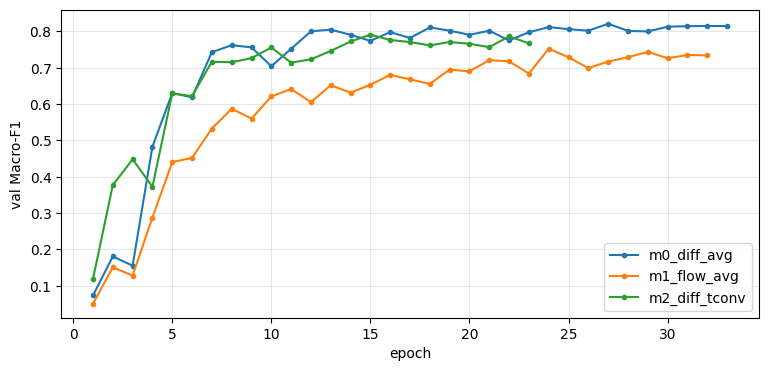


m0_diff_avg: các cặp nhầm nhiều nhất trên test
    true     pred  count
     Tôi Xúc động      2
  Xe máy       Đi      1
Vâng lời  Mời vào      1
  Thương   Nôn ói      1
     Sốt     Biết      1

m1_flow_avg: các cặp nhầm nhiều nhất trên test
    true     pred  count
 Thức ăn       Xa      4
 Mời vào Chậm lại      4
   Chiều       Xa      3
Chậm lại     Chào      2
      Cá  Thức ăn      2

m2_diff_tconv: các cặp nhầm nhiều nhất trên test
   true       pred  count
Thức ăn        Tôi      4
Mời vào Trường học      4
Hôm nay       Ô tô      2
    Tôi   Xúc động      2
 Ủng hộ  Bệnh nhân      1


In [12]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 4))
for r in RUNS:
    p = os.path.join(RUNS_DIR, r, "history.csv")
    if os.path.exists(p):
        h = pd.read_csv(p)
        ax.plot(h.epoch + 1, h.val_macro_f1, marker="o", ms=3, label=r)
ax.set_xlabel("epoch"); ax.set_ylabel("val Macro-F1"); ax.grid(alpha=.3); ax.legend()
plt.savefig(os.path.join(RUNS_DIR, "val_macro_f1.png"), dpi=150, bbox_inches="tight")
plt.show()
for r in RUNS:
    p = os.path.join(RUNS_DIR, r, "test_top_confusions.csv")
    if os.path.exists(p):
        print(f"\n{r}: các cặp nhầm nhiều nhất trên test")
        print(pd.read_csv(p).head(5).to_string(index=False))